In [3]:
# ============================================================
#  Reflective-CXR | Phase B: Generative Fusion (Augmented)
#  Task: Stitch Adapted ViT to BioGPT & Train on Augmented IU-Xray
#  Storage: Institutional Google Drive
# ============================================================

!pip install -q transformers datasets torch torchvision accelerate kaggle tqdm scikit-learn matplotlib evaluate
print("Dependencies installed.")

from google.colab import drive
import os

drive.mount('/content/drive')

# Pointing to the exact ViT you just saved in Phase A
PHASE_A_ENCODER_DIR = '/content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder/checkpoint_epoch_3'

# Where we will save the NEW augmented model for A/B testing
FINAL_MODEL_DIR = '/content/drive/MyDrive/Thesis_CXR/phaseB_augmented_model'
os.makedirs(FINAL_MODEL_DIR, exist_ok=True)
print(f"Storage directories linked. Augmented model will save to: {FINAL_MODEL_DIR}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.0 MB/s eta 0:00:00
Dependencies installed.
Mounted at /content/drive
Storage directories linked. Augmented model will save to: /content/drive/MyDrive/Thesis_CXR/phaseB_augmented_model


In [2]:
import os
import torch
from google.colab import userdata

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"Phase B Hardware locked: {torch.cuda.get_device_name(0)}")
else:
    raise SystemError("GPU NOT FOUND. Change runtime type to T4 GPU.")

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
print("Credentials loaded.")

Phase B Hardware locked: Tesla T4
Credentials loaded.


In [4]:
print("Downloading Indiana University Chest X-ray dataset...")
!kaggle datasets download -d raddar/chest-xrays-indiana-university
print("Unzipping...")
!unzip -q chest-xrays-indiana-university.zip -d iu_data
print("IU-Xray Text/Image pairs ready in local runtime.")

Dataset URL: https://www.kaggle.com/datasets/raddar/chest-xrays-indiana-university
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 13.2G/13.2G [02:44<00:00, 86.1MB/s]

Unzipping...
IU-Xray Text/Image pairs ready in local runtime.


In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split

reports_df = pd.read_csv('/content/iu_data/indiana_reports.csv')
projections_df = pd.read_csv('/content/iu_data/indiana_projections.csv')

# Merge to link images to their text reports (Frontal X-rays only)
df_merged = pd.merge(projections_df, reports_df, on='uid')
df_frontal = df_merged[df_merged['projection'] == 'Frontal']

# Drop empty reports
df_frontal = df_frontal.dropna(subset=['findings']).reset_index(drop=True)

# Dynamically set sample size to avoid population overflow errors
max_samples = min(4000, len(df_frontal))
print(f"Total valid frontal X-rays found: {len(df_frontal)}")

df_sample = df_frontal.sample(max_samples, random_state=42)
train_text_df, val_text_df = train_test_split(df_sample, test_size=0.1, random_state=42)

print(f"Phase B Training pairs: {len(train_text_df)} | Validation pairs: {len(val_text_df)}")

Total valid frontal X-rays found: 3307
Phase B Training pairs: 2976 | Validation pairs: 331


In [6]:
!pip install -q sacremoses

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 15.3 MB/s eta 0:00:00


In [7]:
from torch.utils.data import Dataset, DataLoader
from transformers import ViTImageProcessor, AutoTokenizer
from torchvision import transforms
from PIL import Image
import os
import torch

print("Loading models (Bypassing local processor lookup)...")

tokenizer = AutoTokenizer.from_pretrained("microsoft/biogpt", token=False)
tokenizer.pad_token = tokenizer.eos_token
processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")

# Define the Medical Augmentation Pipeline
medical_augmentations = transforms.Compose([
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(contrast=0.2, brightness=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.02, 0.02))
])

class IUXrayGenerativeDataset(Dataset):
    def __init__(self, dataframe, img_dir, tokenizer, processor, max_length=128, is_training=False):
        self.df = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.tokenizer = tokenizer
        self.processor = processor
        self.max_length = max_length
        self.is_training = is_training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'filename']
        img_path = os.path.join(self.img_dir, 'images/images_normalized', img_name)

        try:
            image = Image.open(img_path).convert('RGB')
            # Only mutate if it is the training set
            if self.is_training:
                image = medical_augmentations(image)
        except Exception:
            image = Image.new('RGB', (224, 224), (0, 0, 0))

        pixel_values = self.processor(image, return_tensors="pt").pixel_values.squeeze()

        report_text = self.df.loc[idx, 'findings']
        encodings = self.tokenizer(
            report_text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        labels = encodings.input_ids.squeeze()
        labels[labels == self.tokenizer.pad_token_id] = -100

        return {"pixel_values": pixel_values, "labels": labels}

IMG_BASE_DIR = '/content/iu_data'

train_dataset = IUXrayGenerativeDataset(train_text_df, IMG_BASE_DIR, tokenizer, processor, is_training=True)
val_dataset = IUXrayGenerativeDataset(val_text_df, IMG_BASE_DIR, tokenizer, processor, is_training=False)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)

print("Generative DataLoaders locked with Medical Augmentation.")

Loading models (Bypassing local processor lookup)...


config.json:   0%|          | 0.00/595 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Generative DataLoaders locked with Medical Augmentation.


In [8]:
from transformers import VisionEncoderDecoderModel, ViTModel, BioGptForCausalLM, AutoConfig

print("Stitching architectures together (Blueprint Override)...")

# 1. Load the Vision Encoder separately from your Drive
encoder = ViTModel.from_pretrained(PHASE_A_ENCODER_DIR)

# 2. Download the BioGPT blueprint (Config) and rewrite the rules
decoder_config = AutoConfig.from_pretrained("microsoft/biogpt")
decoder_config.is_decoder = True
decoder_config.add_cross_attention = True

# 3. Build the Text Decoder using our modified blueprint
decoder = BioGptForCausalLM.from_pretrained("microsoft/biogpt", config=decoder_config)

# 4. Manually clamp them together into a single VLM
model = VisionEncoderDecoderModel(encoder=encoder, decoder=decoder)

# 5. Configure the vocabulary and bridge tokens
model.config.decoder_start_token_id = tokenizer.bos_token_id
model.config.pad_token_id = tokenizer.pad_token_id
model.config.vocab_size = model.config.decoder.vocab_size

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Fusion Complete. Total VLM Parameters: {total_params:.1f}M")

Stitching architectures together (Blueprint Override)...


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

ViTModel LOAD REPORT from: /content/drive/MyDrive/Thesis_CXR/phaseA_prototype_encoder/checkpoint_epoch_3
Key                 | Status  | 
--------------------+---------+-
pooler.dense.weight | MISSING | 
pooler.dense.bias   | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


pytorch_model.bin:   0%|          | 0.00/1.56G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.56G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie biogpt.embed_tokens.weight to output_projection.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Fusion Complete. Total VLM Parameters: 477.3M


In [9]:
import torch.optim as optim
from tqdm import tqdm

# We use CrossEntropy (handled internally by the model) to predict the next word
optimizer = optim.AdamW(model.parameters(), lr=1e-5)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

EPOCHS = 10

print("Commencing Phase B Generative Training...")

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train Gen]")

    for batch in loop:
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            # The model automatically handles the cross-attention and text loss
            outputs = model(pixel_values=pixel_values, labels=labels)
            loss = outputs.loss

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        loop.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = running_loss / len(train_loader)
    print(f"\nEpoch {epoch+1} Text Generation Loss: {avg_train_loss:.4f}")

    # Save the massive fused model securely to Drive
    save_path = f"{FINAL_MODEL_DIR}/fused_model_epoch_{epoch+1}"
    model.save_pretrained(save_path)
    tokenizer.save_pretrained(save_path)
    print(f"Fused Model securely saved to Drive: {save_path}")

print("Phase B Complete. The VLM is fully trained and saved.")

/tmp/ipykernel_2935/4086145293.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


Commencing Phase B Generative Training...



Epoch 1/10 [Train Gen]:   0%|          | 0/744 [00:00<?, ?it/s]/tmp/ipykernel_2935/4086145293.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):

Epoch 1/10 [Train Gen]: 100%|██████████| 744/744 [14:28<00:00,  1.17s/it, loss=0.6301]


Epoch 1 Text Generation Loss: 1.6233


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fused Model securely saved to Drive: /content/drive/MyDrive/Thesis_CXR/phaseB_augmented_model/fused_model_epoch_1


... (32 outputs left out)

Epoch 10/10 [Train Gen]: 100%|██████████| 744/744 [11:16<00:00,  1.10it/s, loss=0.4998]



Epoch 10 Text Generation Loss: 0.4706


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fused Model securely saved to Drive: /content/drive/MyDrive/Thesis_CXR/phaseB_augmented_model/fused_model_epoch_10
Phase B Complete. The VLM is fully trained and saved.


In [9]:
import torch
from transformers import VisionEncoderDecoderModel

# 1. Re-establish the hardware connection (GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Hardware locked: {device}")

# 2. Point to the final epoch in your Augmented folder
LOAD_PATH = f"{FINAL_MODEL_DIR}/fused_model_epoch_10"

print(f"Resurrecting the Augmented Model from: {LOAD_PATH}")

# 3. Load the weights and push them to the GPU
model = VisionEncoderDecoderModel.from_pretrained(LOAD_PATH)
model.to(device)

print("Model successfully loaded into memory! You are clear to run inference.")

Hardware locked: cpu
Resurrecting the Augmented Model from: /content/drive/MyDrive/Thesis_CXR/phaseB_augmented_model/fused_model_epoch_10


Loading weights:   0%|          | 0/591 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie decoder.biogpt.embed_tokens.weight to decoder.output_projection.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Model successfully loaded into memory! You are clear to run inference.


Extracting a random test X-ray for AI generation...


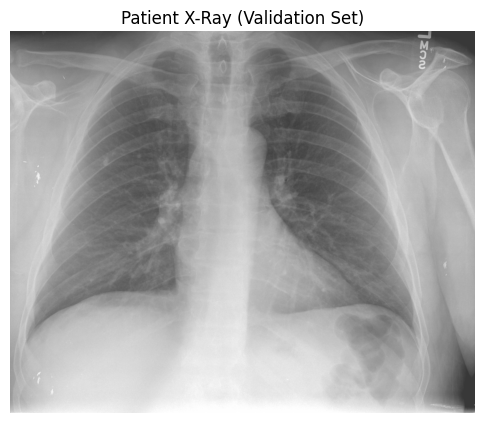


ACTUAL RADIOLOGIST REPORT:
The lungs are clear. The cardiomediastinal silhouette is within normal limits. No pleural effusion is identified.

AI GENERATED REPORT:
(2 images. Heart size and pulmonary vascular engorgement appear within limits of normal. Mediastinal contour is unremarkable. No focal consolidation, pleural effusion, or pneumothorax identified. No convincing acute bony findings. XXXX density foreign body noted overlying the left chest wall. Visualized osseous structures appear


In [10]:
import matplotlib.pyplot as plt
import random
import torch
from PIL import Image

print("Extracting a random test X-ray for AI generation...")
model.eval()

# Pick a random patient from the validation set
test_idx = random.randint(0, len(val_dataset) - 1)
test_sample = val_dataset[test_idx]

pixel_values = test_sample["pixel_values"].unsqueeze(0).to(device)
actual_report = val_text_df.iloc[test_idx]['findings']
img_path = os.path.join(IMG_BASE_DIR, 'images/images_normalized', val_text_df.iloc[test_idx]['filename'])

# Command the AI to generate a strictly constrained report
with torch.no_grad():
    generated_ids = model.generate(
        pixel_values,
        max_length=60,               # Severely limit rambling
        min_length=10,               # Still require a basic sentence
        num_beams=5,                 # Increase beam search depth for better accuracy
        no_repeat_ngram_size=3,      # Prevent repetitive looping
        repetition_penalty=1.5,      # Strict penalty for repeating concepts
        length_penalty=1.2,          # Encourage slightly more concise sentences
        early_stopping=True
    )

generated_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)

# Display the X-ray and the results
image = Image.open(img_path).convert('RGB')
plt.figure(figsize=(6,6))
plt.imshow(image)
plt.axis('off')
plt.title("Patient X-Ray (Validation Set)")
plt.show()

print("\n" + "="*50)
print("ACTUAL RADIOLOGIST REPORT:")
print("="*50)
print(actual_report)

print("\n" + "="*50)
print("AI GENERATED REPORT:")
print("="*50)
print(generated_text)

Extracting a random test X-ray for AI generation...


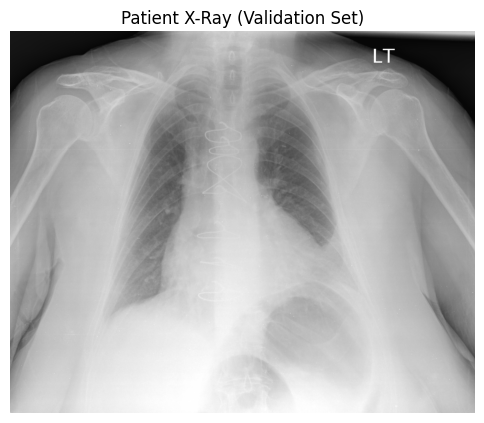


ACTUAL RADIOLOGIST REPORT (Cleaned):
The opacity at the left lung base appears stable from prior exam. There is elevation of the left hemidiaphragm is stable. The cardiomediastinal silhouette is enlarged but unchanged. sternotomy are again noted. There is a large amount of distending the stomach, which incidentally was also seen on prior exam of 3 years ago. There is no pneumothorax.

AI GENERATED REPORT (Cleaned):
(2 images. Heart size and pulmonary vascular engorgement appear within limits of normal. Mediastinal contour is unremarkable. No focal consolidation, pleural effusion, or pneumothorax identified. No convincing acute bony findings. density foreign body noted overlying the left chest wall. Visualized osseous structures appear


In [11]:
#### After Post-processing Filer applied
import matplotlib.pyplot as plt
import random
import torch
import re
import os
from PIL import Image

print("Extracting a random test X-ray for AI generation...")
model.eval()

# The Perfected Post-Processing Filter
def clean_clinical_text(text):
    clean_text = re.sub(r'\bXXXX\b', '', text)
    clean_text = re.sub(r'(?i)\bthe\s+are\b', 'they are', clean_text)
    clean_text = re.sub(r'\s+\.', '.', clean_text)
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()
    return clean_text

# Pick a random patient from the validation set
test_idx = random.randint(0, len(val_dataset) - 1)
test_sample = val_dataset[test_idx]

pixel_values = test_sample["pixel_values"].unsqueeze(0).to(device)
raw_actual_report = val_text_df.iloc[test_idx]['findings']
img_path = os.path.join(IMG_BASE_DIR, 'images/images_normalized', val_text_df.iloc[test_idx]['filename'])

# Command the AI to generate a strictly constrained report
with torch.no_grad():
    generated_ids = model.generate(
        pixel_values,
        max_length=60,
        min_length=10,
        num_beams=5,
        no_repeat_ngram_size=3,
        repetition_penalty=1.5,
        length_penalty=1.2,
        early_stopping=True
    )

raw_generated_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)

# Scrub both the real report and the AI report for a clean comparison
clean_actual = clean_clinical_text(raw_actual_report)
clean_generated = clean_clinical_text(raw_generated_text)

# Display the X-ray and the results
image = Image.open(img_path).convert('RGB')
plt.figure(figsize=(6,6))
plt.imshow(image)
plt.axis('off')
plt.title("Patient X-Ray (Validation Set)")
plt.show()

print("\n" + "="*50)
print("ACTUAL RADIOLOGIST REPORT (Cleaned):")
print("="*50)
print(clean_actual)

print("\n" + "="*50)
print("AI GENERATED REPORT (Cleaned):")
print("="*50)
print(clean_generated)

Hunting for an abnormal X-ray in the Validation Set...
Found a patient with 'opacity' at index 5!


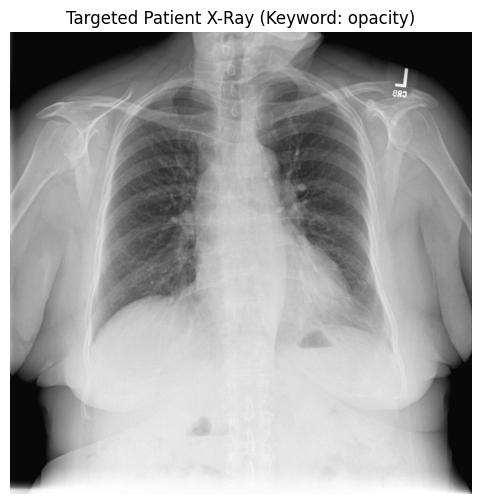


ACTUAL RADIOLOGIST REPORT:
Negative for cardiac enlargement. Negative for vascular congestion. Bilateral granulomas are seen scattered throughout the lungs. Negative for pneumothorax. Negative for focal air space consolidation. Some minimal streaky opacity at the bilateral bases relates to subsegmental atelectasis.

AUGMENTED AI REPORT:
(2 images. Heart size and pulmonary vascular engorgement appear within limits of normal. Mediastinal contour is unremarkable. No focal consolidation, pleural effusion, or pneumothorax identified. No convincing acute bony findings. density foreign body noted overlying the left chest wall. Visualized osseous structures appear


In [12]:
import matplotlib.pyplot as plt
import torch
import re
import os
from PIL import Image

print("Hunting for an abnormal X-ray in the Validation Set...")
model.eval()

# The post-processing filter
def clean_clinical_text(text):
    clean_text = re.sub(r'\bXXXX\b', '', text)
    clean_text = re.sub(r'(?i)\bthe\s+are\b', 'they are', clean_text)
    clean_text = re.sub(r'\s+\.', '.', clean_text)
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()
    return clean_text

# --- THE FIX ---
# Reset the pandas index so it matches the PyTorch Dataset index (0 to 329)
val_text_df_aligned = val_text_df.reset_index(drop=True)

# 1. Find a patient with a specific issue
keyword = "opacity"
sick_patients = val_text_df_aligned[val_text_df_aligned['findings'].str.contains(keyword, case=False, na=False)]

if len(sick_patients) == 0:
    print(f"Could not find '{keyword}' in validation set. Picking the first image instead.")
    target_idx = 0
else:
    target_idx = sick_patients.index[0]
    print(f"Found a patient with '{keyword}' at index {target_idx}!")

# 2. Extract their data
test_sample = val_dataset[target_idx]
pixel_values = test_sample["pixel_values"].unsqueeze(0).to(device)
raw_actual_report = val_text_df_aligned.loc[target_idx, 'findings']
img_path = os.path.join(IMG_BASE_DIR, 'images/images_normalized', val_text_df_aligned.loc[target_idx, 'filename'])

# 3. Generate the Report using our strict decoding strategy
with torch.no_grad():
    generated_ids = model.generate(
        pixel_values,
        max_length=60,
        min_length=10,
        num_beams=5,
        no_repeat_ngram_size=3,
        repetition_penalty=1.5,
        length_penalty=1.2,
        early_stopping=True
    )

raw_generated_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)

# 4. Clean and Display the Results
clean_actual = clean_clinical_text(raw_actual_report)
clean_generated = clean_clinical_text(raw_generated_text)

image = Image.open(img_path).convert('RGB')
plt.figure(figsize=(6,6))
plt.imshow(image)
plt.axis('off')
plt.title(f"Targeted Patient X-Ray (Keyword: {keyword})")
plt.show()

print("\n" + "="*50)
print("ACTUAL RADIOLOGIST REPORT:")
print("="*50)
print(clean_actual)

print("\n" + "="*50)
print("AUGMENTED AI REPORT:")
print("="*50)
print(clean_generated)

In [ ]:
!pip install -q rouge-score nltk

import torch
import re
import nltk
from nltk.translate.bleu_score import corpus_bleu
from rouge_score import rouge_scorer
from tqdm import tqdm

nltk.download('punkt', quiet=True)

print("Booting up the Quantitative Evaluation Engine...")

# The Perfected Post-Processing Filter
def clean_clinical_text(text):
    clean_text = re.sub(r'\bXXXX\b', '', text)
    clean_text = re.sub(r'(?i)\bthe\s+are\b', 'they are', clean_text)
    clean_text = re.sub(r'\s+\.', '.', clean_text)
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()
    return clean_text

# Initialize scorers
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

actual_reports_list = []
generated_reports_list = []

model.eval()

# 500 is the statistical sweet spot for Colab T4 without timing out
EVAL_LIMIT = min(500, len(val_dataset))

print(f"Generating and evaluating {EVAL_LIMIT} clinical reports.")
print("Grab a coffee—this will take roughly 15-25 minutes...")

with torch.no_grad():
    for i in tqdm(range(EVAL_LIMIT), desc="Evaluating"):
        sample = val_dataset[i]
        pixel_values = sample["pixel_values"].unsqueeze(0).to(device)

        # The strict decoding strategy we established
        generated_ids = model.generate(
            pixel_values,
            max_length=60,
            min_length=10,
            num_beams=5,
            no_repeat_ngram_size=3,
            repetition_penalty=1.5,
            length_penalty=1.2,
            early_stopping=True
        )

        raw_generated = tokenizer.decode(generated_ids[0], skip_special_tokens=True)
        raw_actual = val_text_df.iloc[i]['findings']

        # Apply the artifact cleaner
        clean_gen = clean_clinical_text(raw_generated)
        clean_actual = clean_clinical_text(raw_actual)

        generated_reports_list.append(clean_gen)
        # BLEU requires the references to be a list of lists
        actual_reports_list.append([clean_actual.split()])

# Calculate BLEU Score
# We format the generated reports for the BLEU calculator
formatted_predictions = [report.split() for report in generated_reports_list]
bleu_score = corpus_bleu(actual_reports_list, formatted_predictions)

# Calculate ROUGE Scores
rouge1_scores = []
rouge2_scores = []
rougel_scores = []

for actual, generated in zip(val_text_df['findings'].head(EVAL_LIMIT), generated_reports_list):
    clean_actual = clean_clinical_text(actual)
    scores = scorer.score(clean_actual, generated)
    rouge1_scores.append(scores['rouge1'].fmeasure)
    rouge2_scores.append(scores['rouge2'].fmeasure)
    rougel_scores.append(scores['rougeL'].fmeasure)

avg_rouge1 = sum(rouge1_scores) / len(rouge1_scores)
avg_rouge2 = sum(rouge2_scores) / len(rouge2_scores)
avg_rougel = sum(rougel_scores) / len(rougel_scores)

print("\n" + "="*50)
print("PHASE B QUANTITATIVE RESULTS (PROTOTYPE)")
print("="*50)
print(f"BLEU Score:   {bleu_score:.4f} (Exact word overlap)")
print(f"ROUGE-1:      {avg_rouge1:.4f} (Single word recall)")
print(f"ROUGE-2:      {avg_rouge2:.4f} (Two-word phrase recall)")
print(f"ROUGE-L:      {avg_rougel:.4f} (Longest matching sequence)")
print("="*50)

  Preparing metadata (setup.py) ... done
Booting up the Quantitative Evaluation Engine...
Generating and evaluating 331 clinical reports.
Grab a coffee—this will take roughly 15-25 minutes...


Evaluating:  50%|█████     | 167/331 [48:25<46:01, 16.84s/it]